In [1]:
### NOTES 

### - Euclidean distance does pretty well overall
###   I think the claim could be that we can sort the volumes in a single shot,
###   whereas to get the correct ordering with L2, you probably have to compute
###   the distance sequentially (i.e. starting with the new nearest neighbor).
###   [should probably confirm this with other data too]

### - Make a distance thats linear combination of L2 and SW ?

In [2]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### other
import mrcfile

### my modules
from fast_volume_align_ot import utils, plots, transforms, signals, fle_3d, alignments

In [3]:
#######################################


### *** HETEROGENEOUS DISTANCE *** ###


#######################################

In [4]:
### INPUTS

n_vols = 25

scale = 1

In [5]:
het_vol_files = 'Data/het_models/'

het_vols = []
vol_idx = np.linspace(0, 49, n_vols, endpoint=True).astype('int')

for k in vol_idx:
    with mrcfile.open(het_vol_files+'{}'.format(k)+'.mrc', permissive=True) as mrc:
        v = mrc.data
        dx = mrc.voxel_size.x
        
        v = transforms.block_average_downsample(v, scale)
        dx = dx * scale
            
        v = np.pad(v, pad_width=((0, 1), (0, 1), (0, 1)))  ### zero-pad to make odd size  
        v = signals.Signal(v, d=3, dx=dx).preprocess_signals()[0]
        
        het_vols.append(v)
        mrc.close()

het_vols = np.array(het_vols)

f = het_vols[0].copy()

/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:206: RuntimeWarning: Map ID string not found - not an MRC file, or file is corrupt
  warnings.warn(msg, RuntimeWarning)
/Users/Eric-Verbeke/miniforge3/envs/fsw3d/lib/python3.9/site-packages/mrcfile/mrcinterpreter.py:216: RuntimeWarning: Unrecognised machine stamp: 0x00 0x00 0x00 0x00
  warnings.warn(str(err), RuntimeWarning)


In [6]:
### Define constants

d = 3  # dimensons
N = f.shape[0]

# z = np.linspace(-1, 1, N, endpoint=False)
z = np.linspace(0, 1, N, endpoint=False)
phis = np.linspace(0, 2*np.pi, N, endpoint=False)
thetas = np.linspace(0, np.pi, N, endpoint=True)

sinthetas = np.sin(thetas)[np.newaxis, np.newaxis, :]

dV = dx**3  # for the voxel grid
dVsphere = (z[1]-z[0])*(thetas[1]-thetas[0])*(phis[1]-phis[0]) 

print(dVsphere)

9.267025345052654e-06


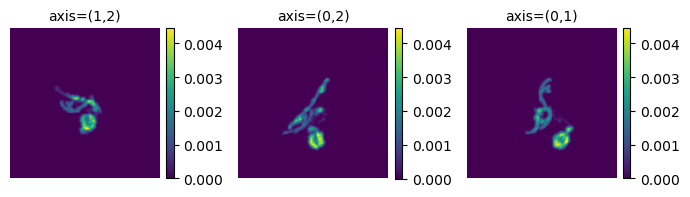

0.0 0.0004249569 0.9999999 0.9999998807907104


In [7]:
plots.orthogonal_2D_projection_plot(f)
print( np.amin(f), np.amax(f), np.sum(f), np.sum(f)*(dV) )

In [8]:
# a = np.linalg.norm(f_t * np.sqrt(sinthetas))
# b = np.sqrt(np.sum(f_t**2 * sinthetas))
# np.allclose(a, b)

In [9]:
### Compute the squared distances

distances_l2 = np.zeros(n_vols)
distances_sw = np.zeros(n_vols)
distances_rfsw = np.zeros(n_vols)

f_t = transforms.Transform(f, d=3).inverse_cdf_transform()[0]
f_tp, f_tn = transforms.Transform(f, d=3, apply_ramp=True).signed_inverse_cdf_transform()

for k in range(n_vols):

    g = het_vols[k]

    ### Euclidean distance
    d_l2 = np.linalg.norm(f - g)**2
    distances_l2[k] = d_l2

    ### sliced 2-Wasserstein distance
    g_t = transforms.Transform(g, d=3).inverse_cdf_transform()[0]
    d_sw = np.sum((f_t - g_t)**2 * sinthetas) * dVsphere / (4*np.pi)
    distances_sw[k] = d_sw

    ### ramp-filtered sliced 2-Wasserstein distance
    g_tp, g_tn = transforms.Transform(g, d=3, apply_ramp=True).signed_inverse_cdf_transform()
    d_sw_p = np.sum((f_tp[0] - g_tp[0])**2 * sinthetas) * dVsphere / (4*np.pi)
    d_sw_n = np.sum((f_tn[0] - g_tn[0])**2 * sinthetas) * dVsphere / (4*np.pi)
    d_rfsw = (d_sw_p + d_sw_n) / 2
    distances_rfsw[k] = d_rfsw

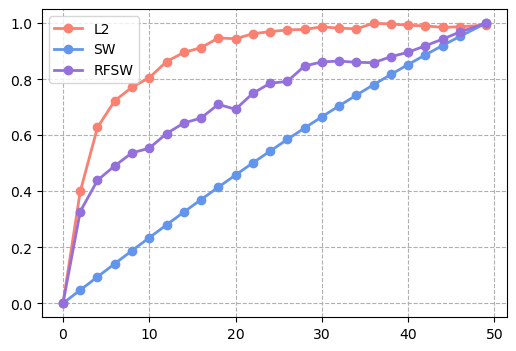

In [10]:
### EV: not sure if things should be on same scale, so normalize
dists_l2 = np.sqrt( distances_l2 / np.amax(distances_l2) )
dists_sw = np.sqrt( distances_sw / np.amax(distances_sw) )
dists_rfsw = np.sqrt( distances_rfsw / np.amax(distances_rfsw) )

plt.figure(figsize=(6,4))
plt.plot(vol_idx[:], dists_l2, color='salmon', marker='o', linewidth=2, label='L2')
plt.plot(vol_idx[:], dists_sw, color='cornflowerblue', marker='o', linewidth=2, label='SW')
plt.plot(vol_idx[:], dists_rfsw, color='mediumpurple', marker='o', linewidth=2, label='RFSW')
plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

  L2:  [ 0  1  2  3  4  5  6  7  8 10  9 11 12 13 14 17 16 22 15 23 21 20 24 19
 18]
  SW:  [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24]
RFSW:  [ 0  1  2  3  4  5  6  7  8 10  9 11 12 13 14 18 17 15 16 19 20 21 22 23
 24]


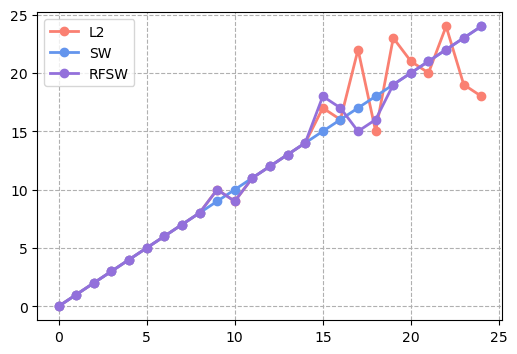

In [11]:
print("  L2: ", np.argsort(dists_l2))
print("  SW: ", np.argsort(dists_sw))
print("RFSW: ", np.argsort(dists_rfsw))

plt.figure(figsize=(6,4))
plt.plot(np.argsort(dists_l2), color='salmon', marker='o', linewidth=2, label='L2')
plt.plot(np.argsort(dists_sw), color='cornflowerblue', marker='o', linewidth=2, label='SW')
plt.plot(np.argsort(dists_rfsw), color='mediumpurple', marker='o', linewidth=2, label='RFSW')
plt.grid(which='major', linestyle='--')
plt.legend()
plt.show()

In [12]:
########################################


### *** STABILITY TO TRANSLATION *** ###


########################################

In [13]:
# ### If want to use the triple Gaussian

# N = 37
# sigma = 2
# f = utils.generate_3d_triangle_gaussian_shape(N, sigma)
# f = signals.Signal(f, d=3).preprocess_signals()

# ### zero pad to allow for shifting
# w = 15
# f = np.pad(f[0], pad_width=((w, w), (w, w), (w, w)))
# N = f.shape[0]
# print(f.shape)

# z = np.linspace(-1, 1, N, endpoint=False)
# phis = np.linspace(0, 2*np.pi, N, endpoint=False)
# thetas = np.linspace(0, np.pi, N, endpoint=True)
# sinthetas = np.sin(thetas)[np.newaxis, np.newaxis, :]
# dVsphere = (z[1]-z[0])*(thetas[1]-thetas[0])*(phis[1]-phis[0]) 

# print(dVsphere)

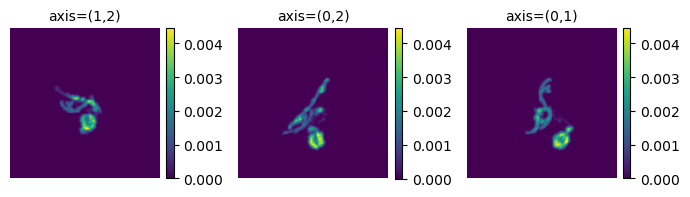

In [14]:
plots.orthogonal_2D_projection_plot(f)

In [15]:
### Compute the squared distances

n_shifts = 25
shifts = np.arange(n_shifts)

distances_l2 = np.zeros(n_shifts)
distances_sw = np.zeros(n_shifts)
distances_rfsw = np.zeros(n_shifts)

f_t = transforms.Transform(f, d=3).inverse_cdf_transform()[0]
f_tp, f_tn = transforms.Transform(f, d=3, apply_ramp=True).signed_inverse_cdf_transform()

for s in range(n_shifts):

    g = transforms.translate_3d(f, 0, 0, s)

    ### Euclidean distance
    d_l2 = np.linalg.norm(f - g)**2
    distances_l2[s] = d_l2

    ### sliced 2-Wasserstein distance
    g_t = transforms.Transform(g, d=3).inverse_cdf_transform()[0]
    d_sw = np.sum((f_t - g_t)**2 * sinthetas) * dVsphere / (4*np.pi)
    distances_sw[s] = d_sw

    ### ramp-filtered sliced 2-Wasserstein distance
    g_tp, g_tn = transforms.Transform(g, d=3, apply_ramp=True).signed_inverse_cdf_transform()
    d_sw_p = np.sum((f_tp[0] - g_tp[0])**2 * sinthetas) * dVsphere / (4*np.pi)
    d_sw_n = np.sum((f_tn[0] - g_tn[0])**2 * sinthetas) * dVsphere / (4*np.pi)
    d_rfsw = (d_sw_p + d_sw_n) / 2
    distances_rfsw[s] = d_rfsw

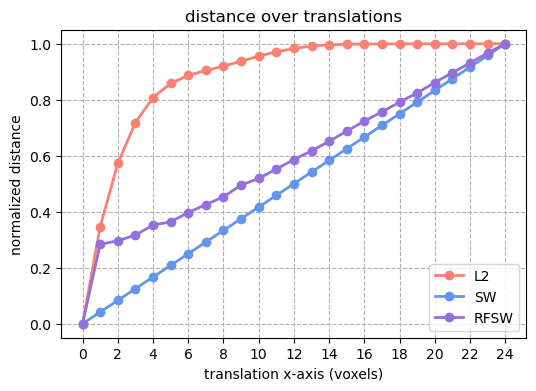

In [16]:
### EV: not sure if things should be on same scale, so normalize
dists_l2 = np.sqrt( distances_l2 / np.amax(distances_l2) )
dists_sw = np.sqrt( distances_sw / np.amax(distances_sw) )
dists_rfsw = np.sqrt( distances_rfsw / np.amax(distances_rfsw) )

plt.figure(figsize=(6,4))
plt.plot(shifts, dists_l2, color='salmon', marker='o', linewidth=2, label='L2')
plt.plot(shifts, dists_sw, color='cornflowerblue', marker='o', linewidth=2, label='SW')
plt.plot(shifts, dists_rfsw, color='mediumpurple', marker='o', linewidth=2, label='RFSW')

plt.xticks(shifts[::2])
plt.grid(which='major', linestyle='--')
plt.xlabel('translation x-axis (voxels)')
plt.ylabel('normalized distance')
plt.title('distance over translations')
plt.legend()
plt.show()

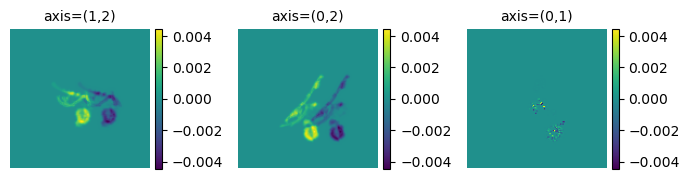

In [17]:
plots.orthogonal_2D_projection_plot(f - g)

In [18]:
a = np.sum((f_t - g_t)**2 * sinthetas) * dVsphere 


b = (np.sum(f_t**2 * sinthetas) + np.sum(g_t**2 * sinthetas) - 2*np.sum(f_t * g_t * sinthetas)) * dVsphere

In [19]:
np.allclose(a, b)

True